In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una obra de reforma integral comprende las actividades del cuadro adjunto (duraciones en semanas). La actividad **E** es la demolición selectiva: incluye desmontar, separar y acopiar por fracciones lo que se retira. Las toneladas de residuo que genera cada actividad, por fracción, se adjuntan (hormigón, cerámica, madera, metal, yeso y plástico; el estudio de gestión de residuos del proyecto prevé que el hormigón y la cerámica vayan a planta de reciclado de áridos, la madera y el metal a valorización y el yeso y el plástico a gestor específico).

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado (residuos en toneladas)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, hormigon, ceramica, madera, metal, yeso, plastico
    ('A'     , '---'      , 7       , 0       , 0       , 0     , 0    , 0   , 0       ),
    ('B'     , '---'      , 3       , 75      , 14      , 6     , 2    , 11  , 2       ),
    ('C'     , '---'      , 2       , 52      , 14      , 4     , 1    , 2   , 1       ),
    ('D'     , 'A,B,C'    , 1       , 0       , 0       , 0     , 0    , 0   , 0       ),
    ('E'     , 'D'        , 3       , 65      , 5       , 6     , 3    , 4   , 0       ),
    ('F'     , 'E'        , 6       , 21      , 27      , 3     , 7    , 3   , 1       ),
    ('G'     , 'E'        , 5       , 0       , 0       , 0     , 0    , 0   , 0       ),
    ('H'     , 'F,G'      , 2       , 0       , 0       , 0     , 0    , 0   , 0       ),
    ('I'     , 'H'        , 2       , 0       , 0       , 0     , 0    , 0   , 0       ),
], columns=['activity', 'predecessor', 'duration', 'hormigon', 'ceramica', 'madera', 'metal', 'yeso', 'plastico']).set_index('activity')
datos_enunciado

,predecessor,duration,hormigon,ceramica,madera,metal,yeso,plastico
activity,,,,,,,,
A,---,7,0,0,0,0,0,0
B,---,3,75,14,6,2,11,2
C,---,2,52,14,4,1,2,1
D,"A,B,C",1,0,0,0,0,0,0
E,D,3,65,5,6,3,4,0
F,E,6,21,27,3,7,3,1
G,E,5,0,0,0,0,0,0
H,"F,G",2,0,0,0,0,0,0
I,H,2,0,0,0,0,0,0


Tarifas del gestor (€ por tonelada, impuesto no incluido): hormigón 6, cerámica 8, madera 25, metal -120 (se cobra), yeso 45, plástico 60; residuo mezclado a vertedero de no peligrosos, 38 €/t más el impuesto al depósito (a efectos del impuesto, hormigón y cerámica son la parte inerte del contenedor). El coste semanal del equipo de obra es de 15 k€.

> **De: Jefe de obra**
> Demolición mecánica y un solo contenedor para todo: E se hace en 1 semanas en vez de 3, y nos ahorramos el acopio por fracciones, que ocupa media obra. El gestor se lo lleva a su vertedero y nos olvidamos; es como se ha hecho siempre.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S8 — Jerarquía de residuos y separación en origen.** El orden es prevención, preparación para la reutilización, reciclado, otra valorización y, en último lugar, eliminación. Los residuos de construcción y demolición no peligrosos se clasifican, preferentemente en la obra, en al menos seis fracciones (madera, minerales, metales, vidrio, plástico y yeso) y la demolición es selectiva, previo estudio de las cantidades de cada fracción. Mezclarlo todo en un contenedor que va a vertedero es elegir el último escalón e incumplir la obligación de clasificar. *(cf. Ley 7/2022 de residuos y suelos contaminados, arts. 8 y 30; RD 105/2008 (estudio y plan de gestión de RCD).)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **Norma o dato de referencia — los residuos de construcción y demolición no peligrosos se clasifican, preferentemente en la obra, en al menos seis fracciones (madera, minerales, metales, vidrio, plástico y yeso) desde el 1 de julio de 2022 (art. 30.2); desde el 1 de enero de 2024 la demolición se lleva a cabo preferiblemente de forma selectiva —y con carácter obligatorio en los supuestos que se desarrollen reglamentariamente—, garantizando la retirada de al menos esas fracciones, previo estudio de las cantidades de cada una (art. 30.3)** *(Ley 7/2022, art. 30.2 y 30.3.)*
- **Norma o dato de referencia — impuesto estatal al depósito en vertedero: en vertedero de residuos no peligrosos, 10 € por tonelada para los residuos no municipales que han pasado por tratamiento previo (15 € si están eximidos de él); si la parte inerte supera el 75 %, esa parte paga 1,5 € por tonelada (3 € si eximidos); en vertedero de inertes, 1,5 € por tonelada; el residuo que se recicla o valoriza no paga el impuesto** *(Ley 7/2022, art. 93.1.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule la duración del proyecto con la demolición selectiva y con la mecánica (E 2 semana(s) más corta). ¿Cuántas semanas ahorra la propuesta y cuánto valen al coste semanal del equipo?  "
pregunta_2 = "2. (A) Calcule el coste de gestión de los residuos en las dos opciones (tarifas más impuesto al vertido) y la fracción del residuo que se valoriza en cada una. ¿Cuál es el resultado económico neto de la propuesta?  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse la propuesta del jefe de obra? ¿Qué fracciones hay que separar y en qué escalón de la jerarquía de residuos queda cada opción?  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de obra y qué comunica a la dirección facultativa? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule la duración del proyecto con la demolición selectiva y con la mecánica (E 2 semana(s) más corta). ¿Cuántas semanas ahorra la propuesta y cuánto valen al coste semanal del equipo?  

2. (A) Calcule el coste de gestión de los residuos en las dos opciones (tarifas más impuesto al vertido) y la fracción del residuo que se valoriza en cada una. ¿Cuál es el resultado económico neto de la propuesta?  

3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse la propuesta del jefe de obra? ¿Qué fracciones hay que separar y en qué escalón de la jerarquía de residuos queda cada opción?  

4. (C) ¿Qué propone al jefe de obra y qué comunica a la dirección facultativa? Aplique la rúbrica.  

# Resolución

In [6]:
demolicion, semanas_menos, coste_semana = 'E', 2, 15
fracciones = ['hormigon', 'ceramica', 'madera', 'metal', 'yeso', 'plastico']
tarifa_separado = {'hormigon': 6, 'ceramica': 8, 'madera': 25, 'metal': -120, 'yeso': 45, 'plastico': 60}
tarifa_mixto, impuesto_mixto, impuesto_inerte = 38, 10, 1.5
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{D} = \max\{0+7,\ 0+3,\ 0+2\} = 7$ &nbsp; (A, B, C)
- $T_{E} = 7+1 = 8$ &nbsp; (D)
- $T_{F} = 8+3 = 11$ &nbsp; (E)
- $T_{G} = 8+3 = 11$ &nbsp; (E)
- $T_{H} = \max\{11+6,\ 11+5\} = 17$ &nbsp; (F, G)
- $T_{I} = 17+2 = 19$ &nbsp; (H)
- $T_{\mathrm{Fin}} = 19+2 = 21$ &nbsp; (I)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 21$
- $T_{I}^{*} = 21-2 = 19$ &nbsp; (Fin)
- $T_{H}^{*} = 19-2 = 17$ &nbsp; (I)
- $T_{G}^{*} = 17-5 = 12$ &nbsp; (H)
- $T_{F}^{*} = 17-6 = 11$ &nbsp; (H)
- $T_{E}^{*} = \min\{11-3,\ 12-3\} = 8$ &nbsp; (F, G)
- $T_{D}^{*} = 8-1 = 7$ &nbsp; (E)
- $T_{C}^{*} = 7-2 = 5$ &nbsp; (D)
- $T_{B}^{*} = 7-3 = 4$ &nbsp; (D)
- $T_{A}^{*} = 7-7 = 0$ &nbsp; (D)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 4-0,\ 5-0\} = 0$ &nbsp; (A, B, C)

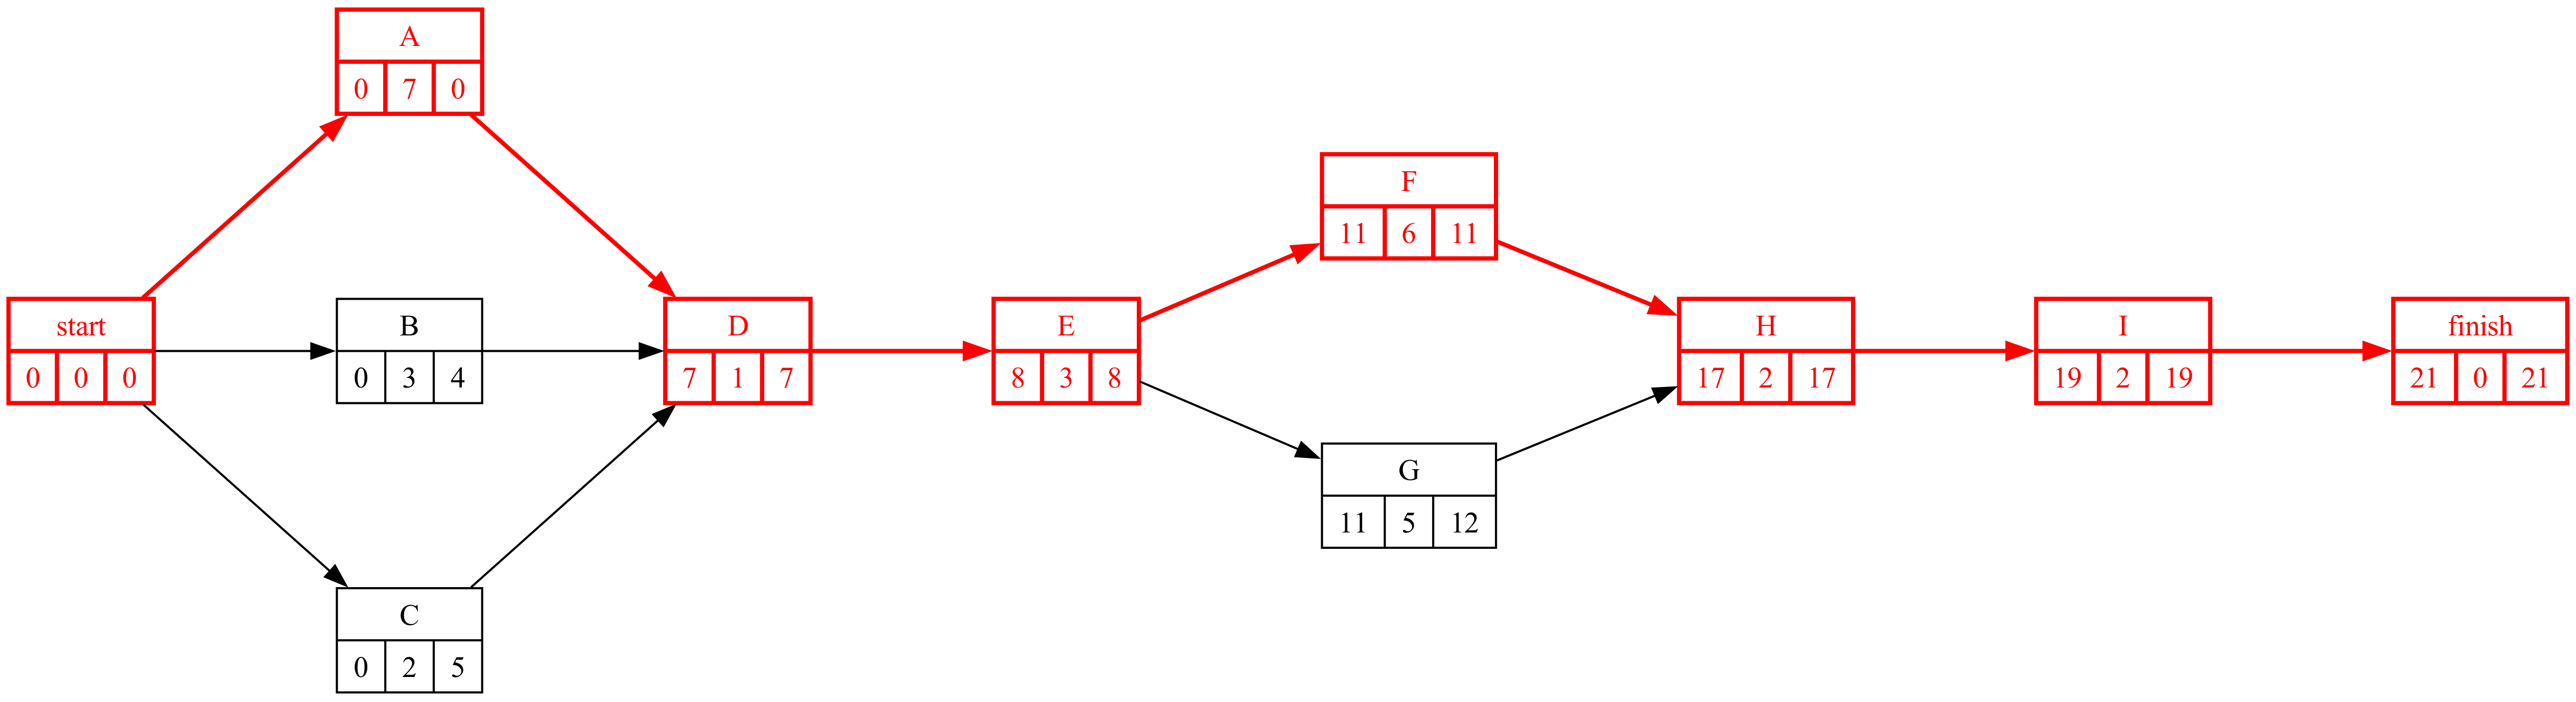

In [8]:
#| fig-cap: "Grafo Roy con la demolición selectiva"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule la duración del proyecto con la demolición selectiva y con la mecánica (E 2 semana(s) más corta). ¿Cuántas semanas ahorra la propuesta y cuánto valen al coste semanal del equipo?  

In [10]:
duraciones_mecanica = datos_proyecto['duration'].copy()
duraciones_mecanica[demolicion] -= semanas_menos
duracion_mecanica = int(proyecto.duration(duraciones_mecanica))
ahorro_semanas = duracion - duracion_mecanica
camino = ' / '.join('–'.join(r) for r in proyecto.critical_path(duraciones_mecanica).values())
Markdown(f'''Con demolición selectiva: **{duracion}** semanas; con demolición mecánica: **{duracion_mecanica}** (ruta crítica {camino}). La propuesta ahorra **{ahorro_semanas}** semana(s), que al coste del equipo valen **{ahorro_semanas * coste_semana} k€**.''')

Con demolición selectiva: **21** semanas; con demolición mecánica: **19** (ruta crítica A–D–E–F–H–I). La propuesta ahorra **2** semana(s), que al coste del equipo valen **30 k€**.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. (A) Calcule el coste de gestión de los residuos en las dos opciones (tarifas más impuesto al vertido) y la fracción del residuo que se valoriza en cada una. ¿Cuál es el resultado económico neto de la propuesta?  

In [12]:
#| tbl-cap: "Toneladas por fracción y coste de gestión de cada opción"
#| label: tbl-residuos
toneladas = datos_proyecto[fracciones].sum()
fraccion_inerte = float(toneladas[['hormigon', 'ceramica']].sum()) / float(toneladas.sum())
# Ley 7/2022, art. 93: 10 €/t en vertedero de no peligrosos; si la parte inerte supera el 75 %, esa parte paga 1,5 €/t
impuesto_por_fraccion = pd.Series({c: (impuesto_inerte if (fraccion_inerte > 0.75 and c in ('hormigon', 'ceramica')) else impuesto_mixto) for c in fracciones})
tabla = pd.DataFrame({'toneladas': toneladas,
                      'separado: tarifa (€/t)': pd.Series(tarifa_separado),
                      'separado: coste (€)': toneladas * pd.Series(tarifa_separado),
                      'mixto: tarifa + impuesto (€/t)': tarifa_mixto + impuesto_por_fraccion,
                      'mixto: coste (€)': toneladas * (tarifa_mixto + impuesto_por_fraccion)})
tabla.loc['Total'] = tabla.sum(); tabla.loc['Total', ['separado: tarifa (€/t)', 'mixto: tarifa + impuesto (€/t)']] = None
display(tabla.round(1))
coste_separado = float(tabla.loc['Total', 'separado: coste (€)']) / 1000
coste_mixto = float(tabla.loc['Total', 'mixto: coste (€)']) / 1000
valorizado = float(toneladas[['hormigon', 'ceramica', 'madera', 'metal']].sum()) / float(toneladas.sum())
neto = ahorro_semanas * coste_semana - (coste_mixto - coste_separado)
Markdown(f'''La parte inerte (hormigón y cerámica) es el {fraccion_inerte:.0%} del contenedor''' + (f''': supera el 75 % y paga {impuesto_inerte} €/t; el resto, {impuesto_mixto} €/t. ''' if fraccion_inerte > 0.75 else f''': no supera el 75 % y todo el contenedor paga {impuesto_mixto} €/t. ''') + f'''Gestión separada: **{coste_separado:.1f} k€** (el metal se cobra; las fracciones recicladas no pagan impuesto); mezclado a vertedero: **{coste_mixto:.1f} k€**. Se valoriza el **{valorizado:.0%}** del residuo frente al 0 % en vertedero. Resultado neto de la propuesta: {ahorro_semanas * coste_semana} − {coste_mixto - coste_separado:.1f} = **{neto:.1f} k€**''' + (' (pierde dinero además de incumplir).' if neto < 0 else ' a favor de la propuesta, antes de la sanción.'))

,toneladas,separado: tarifa (€/t),separado: coste (€),mixto: tarifa + impuesto (€/t),mixto: coste (€)
hormigon,213.0,6.0,1278.0,39.5,8413.5
ceramica,60.0,8.0,480.0,39.5,2370.0
madera,19.0,25.0,475.0,48.0,912.0
metal,13.0,-120.0,-1560.0,48.0,624.0
yeso,20.0,45.0,900.0,48.0,960.0
plastico,4.0,60.0,240.0,48.0,192.0
Total,329.0,NaN,1813.0,NaN,13471.5


La parte inerte (hormigón y cerámica) es el 83% del contenedor: supera el 75 % y paga 1.5 €/t; el resto, 10 €/t. Gestión separada: **1.8 k€** (el metal se cobra; las fracciones recicladas no pagan impuesto); mezclado a vertedero: **13.5 k€**. Se valoriza el **93%** del residuo frente al 0 % en vertedero. Resultado neto de la propuesta: 30 − 11.7 = **18.3 k€** a favor de la propuesta, antes de la sanción.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse la propuesta del jefe de obra? ¿Qué fracciones hay que separar y en qué escalón de la jerarquía de residuos queda cada opción?  

**Norma.** Desde el 1 de julio de 2022 los residuos no peligrosos de la obra se clasifican en al menos seis fracciones, preferentemente en la propia obra (Ley 7/2022, art. 30.2), y desde el 1 de enero de 2024 la demolición se hace preferiblemente de forma selectiva, garantizando la retirada de esas fracciones previo estudio de sus cantidades (art. 30.3): la demolición mecánica con contenedor único a vertedero **no puede ejecutarse**, con independencia de lo que ahorre, porque incumple la clasificación del 30.2 aunque se discuta el alcance del 30.3. Hay que separar las seis fracciones que aparecen en la tabla: hormigón y cerámica (minerales), madera, metal, yeso y plástico. **S8.** El contenedor único a vertedero es **eliminación**, el último escalón de la jerarquía, cuando el 93% del residuo tiene reciclado o valorización disponibles; el plan del proyecto está en los escalones de reciclado y valorización. **S1.** Y en la pirámide del PMBOK 8 la propuesta ni siquiera compensa: traslada el impacto. La respuesta B no depende del apartado 2 (que sólo muestra que, además, el ahorro es pequeño frente a la sanción).

In [14]:
preguntas_test = [
    ('Desde 2022, los residuos de construcción y demolición no peligrosos deben clasificarse en al menos…', ['seis fracciones: madera, minerales, metales, vidrio, plástico y yeso', 'dos fracciones: inertes y resto', 'tantas fracciones como quiera el gestor', 'ninguna: el vertedero las separa'],
     'Ley 7/2022, art. 30.2.'),
    ('Llevar a vertedero un residuo que tiene reciclado disponible es, en la jerarquía de residuos…', ['el último escalón: eliminación', 'otra valorización', 'prevención', 'preparación para la reutilización'],
     'S8: prevención > reutilización > reciclado > otra valorización > eliminación.'),
    ('Desde el 1 de enero de 2024, según el art. 30.3 de la Ley 7/2022, la demolición…', ['se lleva a cabo preferiblemente de forma selectiva, garantizando la retirada de al menos las seis fracciones, previo estudio de sus cantidades', 'puede hacerse de forma mecánica si el gestor separa después en planta', 'sólo es selectiva si lo exige el pliego', 'no está regulada: la decide la dirección facultativa'],
     'Ley 7/2022, art. 30.3; la clasificación en seis fracciones del 30.2 es exigible desde el 1-7-2022.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — residuos de obra')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — residuos de obra

::Sostenibilidad 20 — residuos de obra P1::Desde 2022, los residuos de construcción y demolición no peligrosos deben clasificarse en al menos… {=seis fracciones: madera, minerales, metales, vidrio, plástico y yeso ~dos fracciones: inertes y resto ~tantas fracciones como quiera el gestor ~ninguna: el vertedero las separa ####Ley 7/2022, art. 30.2.}

::Sostenibilidad 20 — residuos de obra P2::Llevar a vertedero un residuo que tiene reciclado disponible es, en la jerarquía de residuos… {~preparación para la reutilización =el último escalón: eliminación ~prevención ~otra valorización ####S8: prevención > reutilización > reciclado > otra valorización > eliminación.}

::Sostenibilidad 20 — residuos de obra P3::Desde el 1 de enero de 2024, según el art. 30.3 de la Ley 7/2022, la demolición… {~no está regulada: la decide la dirección facultativa =se lleva a cabo preferiblemente de forma selectiva, garantizando la retirada de al menos las seis fr

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de obra y qué comunica a la dirección facultativa? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al jefe de obra: la opción no está en la tabla (legalidad); si el acopio por fracciones «ocupa media obra», el problema es de espacio y se resuelve con contenedores por fracción retirados con más frecuencia o con separación en planta de un gestor autorizado para ello, no con un vertedero. Si de verdad hacen falta las 2 semana(s), se buscan en otra actividad crítica con Ackoff (lección 10), no en la norma. A la dirección facultativa: el plan de gestión de residuos se cumple como está, con las cifras del apartado 2 (93% valorizado, 1.8 k€). Prueba de publicidad: ¿firmaría el certificado final de obra con el estudio de gestión de residuos incumplido?